# BoQ Nordland VPR — 4-Fold Ensemble

Four contiguous folds on clean moving frames, followed by score-level ensemble inference.


## 1. Environment

In [1]:
# %pip -q install "gdown>=5.2,<6" "pytorch-metric-learning>=2.5,<3" "pandas>=2,<3" "pillow>=10" "matplotlib>=3.7" "tqdm>=4.60"

In [2]:
import hashlib
import json
import os
import pickle
import random
import re
import shutil
import tempfile
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from pytorch_metric_learning import losses
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import models, transforms as T
from torchvision.transforms import InterpolationMode
from tqdm import tqdm
# from google.colab import drive

# drive.mount('/content/drive')
if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU is required for training.')
print('PyTorch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.5.1 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Configuration

Thay đổi `EPOCHS` để đặt số epoch huấn luyện.


In [3]:
DATASET_FILE_ID = '1pz200V4uhEyOTipI8Akas4kwlYF9_YUD'
DATASET_URL = f'https://drive.google.com/file/d/{DATASET_FILE_ID}/view'

EPOCHS = 10
TRAIN_POSITIVE_RADIUS = 0

# WORK_ROOT = Path('/content/nordland_boq')
# ZIP_PATH = WORK_ROOT / 'nordland-part-2020.zip'
# DATA_ROOT = WORK_ROOT / 'data'
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'nordland-part-2020').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / 'data' / 'nordland-part-2020'
ZIP_PATH = PROJECT_ROOT / 'data' / 'nordland-part-2020.zip'
WORK_ROOT = PROJECT_ROOT / 'runs'
# RUN_NAME = f'boq_nordland_{EPOCHS}epochs_v10_frozen_backbone_neg20_win'
FOLD = 0
SPLIT_FILE = PROJECT_ROOT / 'data' / 'splits' / 'nordland_clean_4fold.csv'
RUN_NAME = f'boq_nordland_clean_fold{FOLD}_random_{EPOCHS}ep'
# RUN_DIR = Path('/content/drive/MyDrive/OLPAI2026_VPR/runs') / RUN_NAME
RUN_DIR = WORK_ROOT / RUN_NAME

SEED = 2026
EXPECTED_FIRST_POSITION = 251
EXPECTED_LAST_POSITION = 2000
BUILD_ID = f'boq_nordland_clean_fold{FOLD}_random_{EPOCHS}ep'

CONFIG = {
    'seed': SEED,
    'image_size': 320,
    'groups_per_batch': 8,
    'eval_batch_size': 64,
    # 'num_workers': 2,  # Colab
    'num_workers': 0,  # Windows/Jupyter: avoid worker startup at first batch
    'proj_channels': 512,
    'num_queries': 64,
    'num_layers': 2,
    'output_dim': 8192,
    'nheads': 8,
    'conv_kernel': 3,
    'ffn_ratio': 4,
    'dropout': 0.0,
    'epochs': EPOCHS,
    # 'warmup_epochs': 10,
    'warmup_epochs': 3,
    'lr': 1e-4,
    'weight_decay': 1e-3,
    'token_drop': 0.0,
    'token_drop_block': 4,
    # 'lr_decay_epochs': [10, 20],
    'lr_decay_epochs': [15, 30],
    'lr_gamma': 0.1,
    'mining_margin': 0.1,
    'positive_radius': 10,
    'train_positive_radius': TRAIN_POSITIVE_RADIUS,
    'negative_radius': 20,
}

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

if not isinstance(EPOCHS, int) or EPOCHS < 1:
    raise ValueError('EPOCHS must be a positive integer')
if TRAIN_POSITIVE_RADIUS not in (0, 5):
    raise ValueError('TRAIN_POSITIVE_RADIUS must be 0 or 5')

seed_everything(SEED)
DEVICE = torch.device('cuda')
WORK_ROOT.mkdir(parents=True, exist_ok=True)
print('Dataset:', DATA_ROOT)
print('Run:', RUN_DIR)
print('Configuration:', json.dumps(CONFIG, indent=2))


Dataset: d:\AIO\Project\Nordland-Cross-Season-VPR\data\nordland-part-2020
Run: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_clean_fold0_random_10ep
Configuration: {
  "seed": 2026,
  "image_size": 320,
  "groups_per_batch": 8,
  "eval_batch_size": 64,
  "num_workers": 0,
  "proj_channels": 512,
  "num_queries": 64,
  "num_layers": 2,
  "output_dim": 8192,
  "nheads": 8,
  "conv_kernel": 3,
  "ffn_ratio": 4,
  "dropout": 0.0,
  "epochs": 10,
  "warmup_epochs": 3,
  "lr": 0.0001,
  "weight_decay": 0.001,
  "token_drop": 0.0,
  "token_drop_block": 4,
  "lr_decay_epochs": [
    15,
    30
  ],
  "lr_gamma": 0.1,
  "mining_margin": 0.1,
  "positive_radius": 10,
  "train_positive_radius": 0,
  "negative_radius": 20
}


## 3. Dataset

In [4]:
# uploaded_zip = Path('/content/nordland-part-2020.zip')
# if uploaded_zip.is_file():
#     ZIP_PATH = uploaded_zip
# elif not ZIP_PATH.is_file() or ZIP_PATH.stat().st_size == 0:
#     downloaded = gdown.download(id=DATASET_FILE_ID, output=str(ZIP_PATH), quiet=False)
#     if not downloaded or not ZIP_PATH.is_file():
#         raise RuntimeError('Unable to download the dataset.')

# if not zipfile.is_zipfile(ZIP_PATH):
#     raise ValueError(f'Invalid ZIP: {ZIP_PATH}')

# with zipfile.ZipFile(ZIP_PATH) as archive:
#     image_entries = [entry for entry in archive.infolist()
#                      if not entry.is_dir() and Path(entry.filename).suffix.lower() in ('.jpg', '.jpeg', '.png')]
#     if not image_entries:
#         raise FileNotFoundError('No images found in ZIP.')
#     root = DATA_ROOT.resolve()
#     root.mkdir(parents=True, exist_ok=True)
#     for entry in tqdm(image_entries, desc='Extracting'):
#         target = (root / entry.filename).resolve()
#         if root not in target.parents:
#             raise ValueError(f'Invalid ZIP path: {entry.filename}')
#         if target.exists() and target.stat().st_size == entry.file_size:
#             continue
#         target.parent.mkdir(parents=True, exist_ok=True)
#         with archive.open(entry) as source, target.open('wb') as destination:
#             shutil.copyfileobj(source, destination, length=1024 * 1024)

if not DATA_ROOT.is_dir() or not ZIP_PATH.is_file():
    raise FileNotFoundError(f'Expected local dataset and ZIP at {DATA_ROOT} and {ZIP_PATH}')
print('Images:', sum(1 for p in DATA_ROOT.rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png')))
print('Dataset:', DATA_ROOT)

Images: 3500
Dataset: d:\AIO\Project\Nordland-Cross-Season-VPR\data\nordland-part-2020


In [5]:
def frame_position(path):
    match = re.search(r'(\d+)$', Path(path).stem)
    if match is None:
        raise ValueError(f'Không xác định được position từ tên ảnh: {path}')
    return int(match.group(1))

def load_metadata(root):
    records = []
    for path in sorted(root.rglob('*')):
        if not path.is_file() or path.suffix.lower() not in ('.jpg', '.jpeg', '.png'):
            continue
        seasons = [part.lower() for part in path.parts if part.lower() in ('summer', 'winter')]
        if len(seasons) != 1:
            continue
        position = frame_position(path)
        split = 'unassigned'
        records.append({'id': path.stem, 'path': str(path.resolve()),
                        'season': seasons[0], 'position': position, 'split': split})
    frame = pd.DataFrame(records)
    if frame.empty:
        raise FileNotFoundError('Không tìm thấy ảnh summer/winter trong ZIP')
    if frame.duplicated(['season', 'position']).any():
        raise ValueError('Có nhiều ảnh cùng season và position')
    summer_pos = set(frame.loc[frame.season == 'summer', 'position'])
    winter_pos = set(frame.loc[frame.season == 'winter', 'position'])
    if frame.loc[frame.season == 'summer', 'id'].duplicated().any() or frame.loc[frame.season == 'winter', 'id'].duplicated().any():
        raise ValueError('Duplicate image IDs in the same season')
    if summer_pos != winter_pos:
        raise ValueError('Hai mùa không có danh sách position trùng nhau')
    expected = set(range(EXPECTED_FIRST_POSITION, EXPECTED_LAST_POSITION + 1))
    if summer_pos != expected:
        raise ValueError(f'Dataset không đúng phạm vi dự kiến. Missing={sorted(expected-summer_pos)[:12]}, '
                         f'extra={sorted(summer_pos-expected)[:12]}')
    split = pd.read_csv(SPLIT_FILE).query('fold == @FOLD')[['position', 'split']]
    frame = frame.drop(columns='split').merge(split, on='position', how='left', validate='many_to_one')
    if frame.split.isna().any():
        raise ValueError('Split manifest is missing dataset positions')
    train_pos = set(frame.loc[frame.split == 'train', 'position'])
    val_pos = set(frame.loc[frame.split == 'validation', 'position'])
    if min(abs(a - b) for a in train_pos for b in val_pos) <= 30:
        raise ValueError('Train and validation must be more than 30 frames apart')
    return frame.sort_values(['split', 'position', 'season']).reset_index(drop=True)

def make_exact_pairs(frame):
    train = frame.loc[frame.split == 'train']
    summer = train.loc[train.season == 'summer'].sort_values('position')
    winter = train.loc[train.season == 'winter'].set_index('position')
    if summer.position.duplicated().any() or winter.index.duplicated().any():
        raise ValueError('Mỗi position chỉ được có một ảnh cho mỗi mùa')
    if set(summer.position) != set(winter.index):
        raise ValueError('Mỗi position cần đúng 1 summer và 1 winter')
    pairs = []
    for row in summer.itertuples(index=False):
        pairs.extend([
            {'position': int(row.position), 'season': 'summer', 'path': row.path},
            {'position': int(row.position), 'season': 'winter', 'path': winter.loc[row.position].path},
        ])
    return pd.DataFrame(pairs)

METADATA = load_metadata(DATA_ROOT)
TRAIN_PAIRS = make_exact_pairs(METADATA)
print(METADATA.groupby(['split', 'season']).size().to_string())
print('Training positions:', TRAIN_PAIRS.position.nunique())
print('Validation queries:', len(METADATA[(METADATA.split == 'validation') & (METADATA.season == 'summer')]))
assert TRAIN_PAIRS.groupby('position').size().eq(2).all()

split             season
buffer            summer     30
                  winter     30
holdout           summer     76
                  winter     76
stopped_excluded  summer    509
                  winter    509
train             summer    747
                  winter    747
tunnel_excluded   summer    129
                  winter    129
validation        summer    259
                  winter    259
Training positions: 747
Validation queries: 259


## 4. Data loader

In [6]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def image_transform(train=False):
    ops = [T.Resize((CONFIG['image_size'], CONFIG['image_size']), interpolation=InterpolationMode.BICUBIC)]
    if train:
        ops.append(T.RandAugment(num_ops=3, magnitude=9))
    ops.extend([T.ToTensor(), T.Normalize(MEAN, STD)])
    return T.Compose(ops)

class ImageTable(Dataset):
    def __init__(self, table, transform):
        self.table = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        record = self.table.iloc[index]
        with Image.open(record.path) as image:
            tensor = self.transform(image.convert('RGB'))
        position = int(record.position) if 'position' in self.table.columns else -1
        return tensor, position

class GroupedPairBatchSampler(Sampler):
    def __init__(self, table, groups_per_batch, seed):
        self.pairs = {}
        for index, item in table.reset_index(drop=True).iterrows():
            self.pairs.setdefault(int(item.position), []).append((index, item.season))
        for position, entries in self.pairs.items():
            if len(entries) != 2 or {season for _, season in entries} != {'summer', 'winter'}:
                raise ValueError(f'Position {position}: sampler cần 1 summer + 1 winter')
        self.positions = np.asarray(sorted(self.pairs), dtype=np.int64)
        position_set = set(self.positions.tolist())
        self.neighbors = {p: [q for q in range(p - 5, p + 6) if q != p and q in position_set]
                          for p in self.positions.tolist()}
        self.groups_per_batch = int(groups_per_batch)
        if self.groups_per_batch < 2:
            raise ValueError('places_per_batch phải >= 2')
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        positions_per_batch = 2 * self.groups_per_batch
        shuffled = rng.permutation(self.positions)
        for start in range(0, len(shuffled), positions_per_batch):
            selected = shuffled[start:start + positions_per_batch].tolist()
            if len(selected) < positions_per_batch:
                pool = np.setdiff1d(self.positions, selected)
                selected.extend(rng.choice(pool, positions_per_batch - len(selected), replace=False).tolist())
            indices = [i for p in selected for i, _ in self.pairs[int(p)]]
            yield rng.permutation(indices).tolist()

    def __len__(self):
        positions_per_batch = 2 * self.groups_per_batch
        return (len(self.positions) + positions_per_batch - 1) // positions_per_batch

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_data = ImageTable(TRAIN_PAIRS, image_transform(train=True))
sampler = GroupedPairBatchSampler(TRAIN_PAIRS, CONFIG['groups_per_batch'], SEED)
train_generator = torch.Generator()
train_loader = DataLoader(train_data, batch_sampler=sampler, num_workers=CONFIG['num_workers'],
                          pin_memory=True, worker_init_fn=seed_worker, generator=train_generator)
print('Batch size:', CONFIG['groups_per_batch'] * 4)
print('Batches per epoch:', len(train_loader))

Batch size: 32
Batches per epoch: 47


## 5. ResNet-50 + BoQ

In [7]:
class ResNetBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        if not isinstance(resnet.layer3, nn.Module):
            raise RuntimeError('ResNet-50 initialization failed')
        self.features = nn.Sequential(*list(resnet.children())[:-3])
        self.out_channels = 1024
        for parameter in self.features.parameters():
            parameter.requires_grad_(False)

    def forward(self, images):
        return self.features(images)

    def train(self, mode=True):
        super().train(mode)
        for block in self.features:
            block.eval()
        return self

class BoQBlock(nn.Module):
    def __init__(self, dim, num_queries, nheads, ffn_ratio=2, dropout=0.1):
        super().__init__()
        self.encoder = nn.TransformerEncoderLayer(
            d_model=dim, nhead=nheads, dim_feedforward=ffn_ratio * dim,
            dropout=dropout, batch_first=True
        )
        self.queries = nn.Parameter(torch.randn(1, num_queries, dim) * 0.02)
        self.self_attn = nn.MultiheadAttention(dim, nheads, dropout=dropout, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(dim, nheads, dropout=dropout, batch_first=True)
        self.query_norm = nn.LayerNorm(dim)
        self.output_norm = nn.LayerNorm(dim)

    def forward(self, x, return_attention=False):
        x = self.encoder(x)
        q = self.queries.expand(x.size(0), -1, -1)
        q = self.query_norm(q + self.self_attn(q, q, q, need_weights=False)[0])
        output, attention = self.cross_attn(q, x, x, need_weights=return_attention)
        return x, self.output_norm(output), attention

def region_token_dropout(features, drop=0.4, block=4, training=False):
    tokens = features.flatten(2).transpose(1, 2)
    if not training or drop <= 0:
        return tokens
    batch, channels, height, width = features.shape
    if not 0 < drop < 1 or not 1 <= block <= min(height, width):
        raise ValueError('Invalid token dropout configuration')
    keep = torch.ones(batch, 1, height, width, device=features.device)
    rows = torch.arange(height, device=features.device)[None, :, None]
    cols = torch.arange(width, device=features.device)[None, None, :]
    while 1 - keep.mean() < drop:
        top = torch.randint(height - block + 1, (batch, 1, 1), device=features.device)
        left = torch.randint(width - block + 1, (batch, 1, 1), device=features.device)
        region = (rows >= top) & (rows < top + block) & (cols >= left) & (cols < left + block)
        keep.masked_fill_(region[:, None], 0)
    n_keep = max(1, int(height * width * (1 - drop)))
    score = keep.flatten(1) + 1e-3 * torch.rand(batch, height * width, device=features.device)
    index = score.topk(n_keep, dim=1).indices
    return tokens.gather(1, index[..., None].expand(-1, -1, channels))

class BoQ(nn.Module):
    def __init__(self, in_channels, dim, num_queries, num_layers, output_dim, nheads, conv_kernel=1, ffn_ratio=2, dropout=0.1, token_drop=0.0, token_drop_block=4):
        super().__init__()
        if dim % nheads != 0 or output_dim % dim != 0:
            raise ValueError('Dimensions không hợp lệ')
        self.project = nn.Conv2d(in_channels, dim, kernel_size=conv_kernel, padding=conv_kernel // 2)
        self.input_norm = nn.LayerNorm(dim)
        self.token_drop = token_drop
        self.token_drop_block = token_drop_block
        self.blocks = nn.ModuleList([BoQBlock(dim, num_queries, nheads, ffn_ratio, dropout) for _ in range(num_layers)])
        self.fc = nn.Linear(num_layers * num_queries, output_dim // dim)

    def forward(self, features, return_attention=False):
        projected = self.project(features)
        x = self.input_norm(region_token_dropout(projected, self.token_drop,
                                                  self.token_drop_block, self.training))
        outputs, attentions = [], []
        for block in self.blocks:
            x, aggregated, attention = block(x, return_attention)
            outputs.append(aggregated)
            if return_attention:
                attentions.append(attention)
        output = torch.cat(outputs, dim=1)
        output = self.fc(output.transpose(1, 2)).flatten(1)
        output = F.normalize(output, dim=1)
        return (output, attentions) if return_attention else output

class BoQVPR(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.backbone = ResNetBackbone()
        self.aggregator = BoQ(self.backbone.out_channels, config['proj_channels'],
                              config['num_queries'], config['num_layers'],
                              config['output_dim'], config['nheads'],
                              config.get('conv_kernel', 1), config.get('ffn_ratio', 2), config.get('dropout', 0.1),
                              config.get('token_drop', 0.0), config.get('token_drop_block', 4))

    def forward(self, images, return_attention=False):
        return self.aggregator(self.backbone(images), return_attention)

model = BoQVPR(CONFIG).to(DEVICE)
trainable_backbone = sum(p.numel() for p in model.backbone.parameters() if p.requires_grad)
total_backbone = sum(p.numel() for p in model.backbone.parameters())
assert trainable_backbone == 0
print(f'Trainable backbone: {trainable_backbone:,}/{total_backbone:,}')

Trainable backbone: 0/8,543,296


## 6. Retrieval and loss

In [8]:
@torch.inference_mode()
def encode_images(model, table, device, batch_size, workers):
    if table.empty:
        raise ValueError('Không có ảnh để encode')
    loader = DataLoader(ImageTable(table, image_transform()), batch_size=batch_size,
                        shuffle=False, num_workers=workers, pin_memory=device.type == 'cuda')
    model.eval()
    all_vectors = []
    for images, _ in loader:
        with torch.autocast(device_type='cuda'):
            vectors = model(images.to(device, non_blocking=True))
        all_vectors.append(vectors.float().cpu().numpy())
    return np.concatenate(all_vectors, axis=0)

def topk_search(queries, database, k=10, chunk=128):
    q = np.asarray(queries, dtype=np.float32)
    d = np.asarray(database, dtype=np.float32)
    if q.ndim != 2 or d.ndim != 2 or q.shape[1] != d.shape[1] or not len(d):
        raise ValueError('Descriptor shape không hợp lệ')
    k = min(k, len(d))
    idx_out, sim_out = [], []
    for start in range(0, len(q), chunk):
        scores = q[start:start + chunk] @ d.T
        idx = np.argpartition(-scores, kth=k - 1, axis=1)[:, :k]
        value = np.take_along_axis(scores, idx, axis=1)
        rank = np.argsort(-value, axis=1)
        idx_out.append(np.take_along_axis(idx, rank, axis=1))
        sim_out.append(np.take_along_axis(value, rank, axis=1))
    return np.concatenate(idx_out), np.concatenate(sim_out)

def score_like_competition(predictions, query_ids, database_ids, query_position, db_position, tolerance=10):
    qids = [str(x) for x in query_ids]
    database_set = {str(x) for x in database_ids}
    first = predictions.drop_duplicates('query_id', keep='first')
    guesses = dict(zip(first.query_id.astype(str), first.winter_id.astype(str)))
    correct = 0
    for qid in qids:
        winter = guesses.get(qid)
        if winter in database_set and winter in db_position:
            if abs(int(db_position[winter]) - int(query_position[qid])) <= tolerance:
                correct += 1
    return 100.0 * correct / len(qids) if qids else 0.0

def submission_check(predictions, query_ids, database_ids):
    if list(predictions.columns) != ['query_id', 'winter_id']:
        raise ValueError('Submission columns phải là query_id,winter_id')
    qids = set(map(str, query_ids))
    dbids = set(map(str, database_ids))
    if len(predictions) != len(qids) or predictions.query_id.isna().any() or predictions.winter_id.isna().any():
        raise ValueError('Số dòng hoặc ID rỗng')
    if predictions.query_id.astype(str).duplicated().any():
        raise ValueError('Query ID bị trùng')
    if set(predictions.query_id.astype(str)) != qids:
        raise ValueError('Query bị thiếu hoặc không thuộc tập test')
    if not set(predictions.winter_id.astype(str)).issubset(dbids):
        raise ValueError('Có winter ID không thuộc database')
    return True

def validation_retrieval(model, metadata, split='validation'):
    val = metadata.loc[metadata.split == split]
    query = val.loc[val.season == 'summer'].reset_index(drop=True)
    database = val.loc[val.season == 'winter'].reset_index(drop=True)
    qvec = encode_images(model, query, DEVICE, CONFIG['eval_batch_size'], CONFIG['num_workers'])
    dvec = encode_images(model, database, DEVICE, CONFIG['eval_batch_size'], CONFIG['num_workers'])
    indices, scores = topk_search(qvec, dvec, k=10)
    predicted_ids = database.id.to_numpy()[indices[:, 0]]
    predictions = pd.DataFrame({'query_id': query.id.astype(str), 'winter_id': predicted_ids})
    q_position = dict(zip(query.id.astype(str), query.position))
    d_position = dict(zip(database.id.astype(str), database.position))
    recall1 = score_like_competition(predictions, query.id, database.id, q_position, d_position,
                                     CONFIG['positive_radius'])
    errors = np.abs(database.position.to_numpy()[indices] - query.position.to_numpy()[:, None])
    metrics = {
        'recall_at_1': recall1,
        'recall_at_5': float(np.mean(np.any(errors[:, :5] <= CONFIG['positive_radius'], axis=1)) * 100),
        'recall_at_10': float(np.mean(np.any(errors[:, :10] <= CONFIG['positive_radius'], axis=1)) * 100),
        'median_top1_frame_error': float(np.median(errors[:, 0])),
        'mean_top1_frame_error': float(np.mean(errors[:, 0])),
        'n_queries': len(query),
        'n_database': len(database),
    }
    return metrics, {'queries': query, 'database': database, 'indices': indices,
                     'scores': scores, 'errors': errors, 'predictions': predictions}

def images_in_folder(folder):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(folder)
    paths = sorted(path for path in folder.rglob('*')
                   if path.is_file() and path.suffix.lower() in ('.jpg', '.jpeg', '.png'))
    if not paths:
        raise FileNotFoundError(f'No images in {folder}')
    table = pd.DataFrame({'id': [path.stem for path in paths],
                          'path': [str(path.resolve()) for path in paths]})
    if table.id.duplicated().any():
        raise ValueError(f'Duplicate image IDs in {folder}')
    return table


def predict_folders(model, queries_dir, database_dir, device=DEVICE):
    queries = images_in_folder(queries_dir)
    database = images_in_folder(database_dir)
    query_vectors = encode_images(model, queries, device, CONFIG['eval_batch_size'], CONFIG['num_workers'])
    database_vectors = encode_images(model, database, device, CONFIG['eval_batch_size'], CONFIG['num_workers'])
    indices, _ = topk_search(query_vectors, database_vectors, k=1)
    predictions = pd.DataFrame({'query_id': queries.id.astype(str).to_numpy(),
                                'winter_id': database.id.to_numpy()[indices[:, 0]]})
    submission_check(predictions, queries.id, database.id)
    return predictions


def multi_similarity_indices(descriptors, positions, positive_radius=0, negative_radius=20, margin=0.1):
    labels = positions.long().view(-1)
    diff = (labels[:, None] - labels[None, :]).abs()
    eye = torch.eye(len(labels), device=labels.device, dtype=torch.bool)
    positive = (diff <= positive_radius) & ~eye
    negative = diff > negative_radius
    sim = descriptors.detach().float() @ descriptors.detach().float().T
    pos_a, pos_b = torch.where(positive)
    if len(pos_a) == 0:
        raise ValueError('Batch không có positive pairs')
    lowest_pos_sim = sim.masked_fill(~positive, 2.0).min(dim=1).values
    hard_negative = negative & (sim >= lowest_pos_sim[:, None] - margin)
    has_any = negative.any(dim=1)
    has_hard = hard_negative.any(dim=1)
    needs_fallback = has_any & ~has_hard
    if needs_fallback.any():
        best = sim.masked_fill(~negative, -2.0).argmax(dim=1)
        rows = torch.where(needs_fallback)[0]
        hard_negative[rows, best[rows]] = True
    neg_a, neg_b = torch.where(hard_negative)
    assert not (diff[neg_a, neg_b] <= negative_radius).any()
    return pos_a, pos_b, neg_a, neg_b

LOSS = losses.MultiSimilarityLoss(alpha=1.0, beta=50.0, base=0.0)

## 7. Checks

In [9]:
invalid = pd.DataFrame([
    {'query_id': 'q1', 'winter_id': 'w1'},
    {'query_id': 'q1', 'winter_id': 'w2'},
    {'query_id': 'q2', 'winter_id': 'invalid'},
    {'query_id': 'q3', 'winter_id': 'w3'},
])
score = score_like_competition(invalid, ['q1', 'q2', 'q3', 'q4'],
                              ['w1', 'w2', 'w3'],
                              {'q1': 100, 'q2': 200, 'q3': 300, 'q4': 400},
                              {'w1': 105, 'w2': 201, 'w3': 300})
assert score == 50.0
sample_pairs = pd.DataFrame([
    {'position': p, 'season': s, 'path': 'unused'}
    for p in range(100, 401) for s in ['summer', 'winter']
])
sample_sampler = GroupedPairBatchSampler(sample_pairs, groups_per_batch=8, seed=SEED)
selected = next(iter(sample_sampler))
selected_rows = sample_pairs.iloc[selected]
selected_positions = selected_rows.position.unique()
assert len(selected) == 32 and len(selected_positions) == 16
emb = F.normalize(torch.randn(32, 16, device=DEVICE), dim=-1)
positions = torch.tensor(selected_rows.position.to_numpy(), device=DEVICE)
pos0 = multi_similarity_indices(emb, positions, positive_radius=0, negative_radius=20)
pos5 = multi_similarity_indices(emb, positions, positive_radius=5, negative_radius=20)
assert len(pos0[0]) == 32 and len(pos5[0]) >= len(pos0[0])
assert ((positions[pos5[0]] - positions[pos5[1]]).abs() <= 5).all()
assert ((positions[pos5[2]] - positions[pos5[3]]).abs() > 20).all()
probe = BoQ(in_channels=32, dim=32, num_queries=4, num_layers=2,
            output_dim=128, nheads=4).to(DEVICE)
probe_input = torch.randn(2, 32, 4, 4, device=DEVICE)
probe_output = probe(probe_input)
assert probe_output.shape == (2, 128)
(probe_output ** 2).sum().backward()
assert probe.project.weight.grad is not None
drop_probe = region_token_dropout(torch.randn(2, 8, 20, 20, device=DEVICE),
                                  drop=0.4, block=4, training=True)
assert drop_probe.shape == (2, 240, 8)
full_probe = region_token_dropout(torch.randn(2, 8, 20, 20, device=DEVICE), training=False)
assert full_probe.shape == (2, 400, 8)
print('Sanity checks: PASSED')
del probe, probe_input, probe_output, drop_probe, full_probe, emb
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Sanity checks: PASSED


## 8. Training

Tự động tiếp tục từ checkpoint nếu phiên chạy cùng số epoch bị gián đoạn.


In [10]:
def fingerprint_labels(metadata):
    digest = hashlib.sha256()
    digest.update(DATASET_FILE_ID.encode())
    digest.update(str(FOLD).encode())
    for row in metadata.sort_values(['split', 'position', 'season']).itertuples(index=False):
        digest.update(f'{row.split}|{row.position}|{row.season}|{row.id}\n'.encode())
    return digest.hexdigest()


def capture_rng():
    return {
        'python': random.getstate(),
        'numpy': np.random.get_state(),
        'cpu': torch.get_rng_state(),
        'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    }


def restore_rng(state):
    if state is None:
        raise RuntimeError('Checkpoint missing RNG state')
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['cpu'])
    if torch.cuda.is_available() and state['cuda']:
        torch.cuda.set_rng_state_all(state['cuda'])


def state_to_cpu(state_dict):
    return {key: value.detach().cpu().clone() for key, value in state_dict.items()}


def atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(suffix='.pt', delete=False, dir=str(WORK_ROOT)) as stream:
        local_path = Path(stream.name)
    staged = path.with_suffix('.writing')
    try:
        torch.save(payload, local_path)
        shutil.copyfile(local_path, staged)
        os.replace(staged, path)
    finally:
        local_path.unlink(missing_ok=True)
        staged.unlink(missing_ok=True)


def atomic_csv_save(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    staged = path.with_suffix('.writing')
    frame.to_csv(staged, index=False)
    os.replace(staged, path)


def read_checkpoint(path, expected_key):
    path = Path(path)
    if not path.is_file():
        return None
    try:
        payload = torch.load(path, map_location='cpu', weights_only=False)
    except (EOFError, OSError, RuntimeError, pickle.UnpicklingError) as exc:
        print(f'Unreadable checkpoint: {path} ({type(exc).__name__})')
        return None
    if payload.get('run_key') != expected_key or payload.get('run_name') != RUN_NAME:
        raise RuntimeError(f'Checkpoint does not match this run: {path}')
    if 'model' not in payload or 'epoch' not in payload:
        raise RuntimeError(f'Incomplete checkpoint: {path}')
    return payload


def load_checkpoint(path, model, expected_key):
    state = read_checkpoint(path, expected_key)
    if state is None:
        raise FileNotFoundError(path)
    model.load_state_dict(state['model'], strict=True)
    return state


def recover_best(last_state):
    best_weights = last_state.get('best_model')
    if best_weights is None:
        raise RuntimeError('Cannot recover missing best.pt from last.pt')
    best_state = {
        'run_name': RUN_NAME,
        'run_key': RUN_KEY,
        'epoch': int(last_state['best_epoch']),
        'best_epoch': int(last_state['best_epoch']),
        'best_recall': float(last_state['best_recall']),
        'model': best_weights,
        'resumable': False,
    }
    atomic_torch_save(best_state, BEST_PATH)
    return best_state


def get_resume_state():
    best = read_checkpoint(BEST_PATH, RUN_KEY)
    last = read_checkpoint(LAST_PATH, RUN_KEY)
    if best is None and last is None:
        if BEST_PATH.exists() or LAST_PATH.exists():
            raise RuntimeError('Existing checkpoints are unreadable')
        return None
    if best is None:
        best = recover_best(last)
    if last is None:
        if not best.get('resumable', True):
            raise RuntimeError('No resumable checkpoint is available')
        last = best
    elif best['epoch'] > last['epoch']:
        if not best.get('resumable', True):
            raise RuntimeError('Best checkpoint is not resumable')
        last = best
    if int(best['epoch']) != int(last['best_epoch']):
        if last.get('best_model') is None:
            raise RuntimeError('Best and last checkpoints disagree')
        best = recover_best(last)
    if abs(float(best['best_recall']) - float(last['best_recall'])) > 1e-5:
        raise RuntimeError('Best score mismatch across checkpoints')
    return last


def make_scheduler(optimizer):
    steps_per_epoch = len(train_loader)
    warmup_steps = CONFIG['warmup_epochs'] * steps_per_epoch
    milestones = CONFIG['lr_decay_epochs']

    def lr_lambda(step):
        warmup_scale = min(1.0, (step + 1) / warmup_steps) if warmup_steps else 1.0
        decay_count = sum(step >= epoch * steps_per_epoch for epoch in milestones)
        return warmup_scale * CONFIG['lr_gamma'] ** decay_count

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


DATA_FINGERPRINT = fingerprint_labels(METADATA)
with zipfile.ZipFile(ZIP_PATH) as archive:
    digest = hashlib.sha256()
    for item in sorted(archive.infolist(), key=lambda entry: entry.filename):
        digest.update(f'{item.filename}|{item.file_size}|{item.CRC}\n'.encode())
    ZIP_FINGERPRINT = digest.hexdigest()
def run_signature(config):
    payload = {
        'config': config,
        'data_fingerprint': DATA_FINGERPRINT,
        'zip_fingerprint': ZIP_FINGERPRINT,
        'weights': 'IMAGENET1K_V2',
        'build_id': BUILD_ID,
    }
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

RUN_KEY = run_signature(CONFIG)

BEST_PATH = RUN_DIR / 'checkpoints' / 'best.pt'
LAST_PATH = RUN_DIR / 'checkpoints' / 'last.pt'
HISTORY_PATH = RUN_DIR / 'training_history.csv'
CONFIG_PATH = RUN_DIR / 'run_config.json'
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH.parent.mkdir(parents=True, exist_ok=True)
(RUN_DIR / 'figures').mkdir(exist_ok=True)
(RUN_DIR / 'predictions').mkdir(exist_ok=True)

run_config = {'run_name': RUN_NAME, 'run_key': RUN_KEY,
              'build_id': BUILD_ID, 'dataset_id': DATASET_FILE_ID,
              'config': CONFIG, 'weights': 'IMAGENET1K_V2'}
if CONFIG_PATH.exists():
    saved = json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
    if saved.get('run_key') != RUN_KEY:
        raise RuntimeError(f'Checkpoint folder belongs to another configuration: {RUN_DIR}')
else:
    staged = CONFIG_PATH.with_suffix('.writing')
    staged.write_text(json.dumps(run_config, indent=2), encoding='utf-8')
    os.replace(staged, CONFIG_PATH)


def train_model(model):
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                  lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = make_scheduler(optimizer)
    scaler = torch.amp.GradScaler('cuda')
    first_epoch = 0
    best_recall = -1.0
    best_epoch = -1
    history = []
    best_weights = None
    resume = get_resume_state()
    if resume is not None:
        model.load_state_dict(resume['model'], strict=True)
        optimizer.load_state_dict(resume['optimizer'])
        scheduler.load_state_dict(resume['scheduler'])
        scaler.load_state_dict(resume['scaler'])
        restore_rng(resume.get('rng'))
        first_epoch = int(resume['epoch']) + 1
        best_epoch = int(resume['best_epoch'])
        best_recall = float(resume['best_recall'])
        history = list(resume.get('history', []))
        if resume.get('best_model') is not None:
            best_weights = resume['best_model']
        else:
            saved_best = read_checkpoint(BEST_PATH, RUN_KEY)
            best_weights = saved_best['model'] if saved_best is not None else state_to_cpu(model.state_dict())
        print(f'Resume at epoch {first_epoch + 1} | best {best_recall:.2f}% at epoch {best_epoch + 1}')
    else:
        print('Training from epoch 1')

    for epoch in range(first_epoch, CONFIG['epochs']):
        sampler.epoch = epoch
        train_generator.manual_seed(SEED + epoch)
        model.train()
        torch.cuda.reset_peak_memory_stats(DEVICE)
        total_loss = 0.0
        total_hard_negatives = 0
        total_anchors = 0
        steps = 0
        progress = tqdm(train_loader, desc=f'Epoch {epoch + 1}/{CONFIG["epochs"]}')
        for images, labels in progress:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda'):
                descriptors = model(images)
                pairs = multi_similarity_indices(descriptors.float(), labels,
                                                 CONFIG['train_positive_radius'],
                                                 CONFIG['negative_radius'], CONFIG['mining_margin'])
                loss = LOSS(descriptors.float(), labels, pairs)
            hard_negatives = len(pairs[2])
            total_hard_negatives += hard_negatives
            total_anchors += len(labels)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss at epoch {epoch + 1}')
            scaler.scale(loss).backward()
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            # Advance the schedule only when GradScaler actually performed an optimizer step.
            if scaler.get_scale() >= scale_before:
                scheduler.step()
            total_loss += float(loss.item())
            steps += 1
            progress.set_postfix(loss=f'{total_loss / steps:.4f}', hard_neg=hard_negatives)

        # Capture the training peak before validation starts using additional VRAM.
        torch.cuda.synchronize(DEVICE)
        memory_gib = 1024 ** 3
        train_peak_allocated_gib = torch.cuda.max_memory_allocated(DEVICE) / memory_gib
        train_peak_reserved_gib = torch.cuda.max_memory_reserved(DEVICE) / memory_gib
        gpu_total_gib = torch.cuda.get_device_properties(DEVICE).total_memory / memory_gib
        metrics, _ = validation_retrieval(model, METADATA)
        score = float(metrics['recall_at_1'])
        improved = score > best_recall
        if improved:
            best_recall, best_epoch = score, epoch
        history.append({'epoch': epoch + 1, 'train_loss': total_loss / max(steps, 1),
                        'lr': optimizer.param_groups[0]['lr'], **metrics,
                        'hard_negatives_per_batch': round(total_hard_negatives / max(steps, 1), 2),
                        'hard_negatives_per_anchor': round(total_hard_negatives / max(total_anchors, 1), 2),
                        'train_peak_allocated_gib': round(train_peak_allocated_gib, 2),
                        'train_peak_reserved_gib': round(train_peak_reserved_gib, 2),
                        'gpu_total_gib': round(gpu_total_gib, 2),
                        'best_recall_at_1': best_recall, 'best_epoch': best_epoch + 1})
        save_last = (epoch + 1) % 5 == 0 or epoch + 1 == CONFIG['epochs']
        if improved or save_last:
            state = {
                'run_name': RUN_NAME, 'run_key': RUN_KEY, 'epoch': epoch,
                'best_epoch': best_epoch, 'best_recall': best_recall,
                'model': state_to_cpu(model.state_dict()),
                'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(),
                'scaler': scaler.state_dict(),
                'rng': capture_rng(), 'history': list(history), 'config': CONFIG,
                'resumable': True,
            }
            if improved:
                best_weights = state['model']
                atomic_torch_save(state, BEST_PATH)
            state['best_model'] = best_weights
            if save_last:
                atomic_torch_save(state, LAST_PATH)
        atomic_csv_save(pd.DataFrame(history), HISTORY_PATH)
        row = history[-1]
        print(f"Epoch {row['epoch']}/{CONFIG['epochs']} | loss {row['train_loss']:.4f} | lr {row['lr']:.2e} | mined neg/batch {row['hard_negatives_per_batch']:.1f}")
        print(f"R@1 {row['recall_at_1']:.2f}% | R@5 {row['recall_at_5']:.2f}% | R@10 {row['recall_at_10']:.2f}% | frame error median {row['median_top1_frame_error']:.1f}, mean {row['mean_top1_frame_error']:.1f}")
        print(f"GPU peak {row['train_peak_allocated_gib']:.2f}/{row['train_peak_reserved_gib']:.2f} GiB allocated/reserved | best R@1 {row['best_recall_at_1']:.2f}% (epoch {row['best_epoch']})")

    best = read_checkpoint(BEST_PATH, RUN_KEY)
    if best is None:
        last = read_checkpoint(LAST_PATH, RUN_KEY)
        if last is None:
            raise RuntimeError('Training finished without a checkpoint')
        best = recover_best(last)
    return pd.DataFrame(history)


fold_results = []
for FOLD in range(4):
    if FOLD:
        seed_everything(SEED)
        RUN_NAME = f'boq_nordland_clean_fold{FOLD}_random_{EPOCHS}ep'
        BUILD_ID = RUN_NAME
        RUN_DIR = WORK_ROOT / RUN_NAME
        METADATA = load_metadata(DATA_ROOT)
        TRAIN_PAIRS = make_exact_pairs(METADATA)
        train_data = ImageTable(TRAIN_PAIRS, image_transform(train=True))
        sampler = GroupedPairBatchSampler(TRAIN_PAIRS, CONFIG['groups_per_batch'], SEED)
        train_generator = torch.Generator()
        train_loader = DataLoader(train_data, batch_sampler=sampler, num_workers=CONFIG['num_workers'],
                                  pin_memory=True, worker_init_fn=seed_worker, generator=train_generator)
        DATA_FINGERPRINT = fingerprint_labels(METADATA)
        RUN_KEY = run_signature(CONFIG)
        BEST_PATH = RUN_DIR / 'checkpoints' / 'best.pt'
        LAST_PATH = RUN_DIR / 'checkpoints' / 'last.pt'
        HISTORY_PATH = RUN_DIR / 'training_history.csv'
        CONFIG_PATH = RUN_DIR / 'run_config.json'
        BEST_PATH.parent.mkdir(parents=True, exist_ok=True)
        (RUN_DIR / 'figures').mkdir(exist_ok=True)
        (RUN_DIR / 'predictions').mkdir(exist_ok=True)
        run_config = {'run_name': RUN_NAME, 'run_key': RUN_KEY, 'build_id': BUILD_ID,
                      'dataset_id': DATASET_FILE_ID, 'config': CONFIG, 'weights': 'IMAGENET1K_V2'}
        if CONFIG_PATH.exists():
            if json.loads(CONFIG_PATH.read_text(encoding='utf-8')).get('run_key') != RUN_KEY:
                raise RuntimeError(f'Checkpoint folder belongs to another configuration: {RUN_DIR}')
        else:
            staged = CONFIG_PATH.with_suffix('.writing')
            staged.write_text(json.dumps(run_config, indent=2), encoding='utf-8')
            os.replace(staged, CONFIG_PATH)
        model = BoQVPR(CONFIG).to(DEVICE)
    print(f'\n--- Fold {FOLD}/3: {RUN_NAME} ---')
    HISTORY = train_model(model)
    best_row = HISTORY.loc[HISTORY.recall_at_1.idxmax()]
    last_row = HISTORY.iloc[-1]
    fold_results.append({'fold': FOLD, 'best_epoch': int(best_row.epoch),
                         'best_recall_at_1': float(best_row.recall_at_1),
                         'epoch10_recall_at_1': float(last_row.recall_at_1),
                         'checkpoint': str(BEST_PATH)})
    print('Best checkpoint:', BEST_PATH)
FOLD_RESULTS = pd.DataFrame(fold_results)
atomic_csv_save(FOLD_RESULTS, WORK_ROOT / 'boq_nordland_vpr_4fold_metrics.csv')
print(FOLD_RESULTS.to_string(index=False))
print('4-fold mean R@1, best:', FOLD_RESULTS.best_recall_at_1.mean(),
      '| epoch 10:', FOLD_RESULTS.epoch10_recall_at_1.mean())

# Ensemble is evaluated on the common holdout; fold validation sets overlap other folds' training data.
holdout = METADATA.loc[METADATA.split == 'holdout']
ensemble_queries = holdout.loc[holdout.season == 'summer'].sort_values('position').reset_index(drop=True)
ensemble_database = holdout.loc[holdout.season == 'winter'].sort_values('position').reset_index(drop=True)
ensemble_scores = np.zeros((len(ensemble_queries), len(ensemble_database)), dtype=np.float32)
individual_holdout = []
for fold in range(4):
    checkpoint = WORK_ROOT / f'boq_nordland_clean_fold{fold}_random_{EPOCHS}ep' / 'checkpoints' / 'best.pt'
    payload = torch.load(checkpoint, map_location='cpu', weights_only=False)
    ensemble_model = BoQVPR(CONFIG).to(DEVICE).eval()
    ensemble_model.load_state_dict(payload['model'], strict=True)
    q_desc = encode_images(ensemble_model, ensemble_queries, DEVICE, CONFIG['eval_batch_size'], CONFIG['num_workers'])
    d_desc = encode_images(ensemble_model, ensemble_database, DEVICE, CONFIG['eval_batch_size'], CONFIG['num_workers'])
    scores = q_desc @ d_desc.T
    errors = np.abs(ensemble_database.position.to_numpy()[scores.argmax(1)] - ensemble_queries.position.to_numpy())
    individual_holdout.append({'fold': fold, 'holdout_recall_at_1': float((errors <= 10).mean() * 100)})
    ensemble_scores += scores / 4
    del ensemble_model, q_desc, d_desc, scores
    torch.cuda.empty_cache()
ensemble_pred = ensemble_scores.argmax(1)
ensemble_errors = np.abs(ensemble_database.position.to_numpy()[ensemble_pred] - ensemble_queries.position.to_numpy())
ENSEMBLE_METRICS = pd.DataFrame(individual_holdout + [{
    'fold': 'ensemble', 'holdout_recall_at_1': float((ensemble_errors <= 10).mean() * 100)
}])
atomic_csv_save(ENSEMBLE_METRICS, WORK_ROOT / 'boq_nordland_vpr_ensemble_metrics.csv')
print('\nCommon holdout (positions 1796-1871):')
print(ENSEMBLE_METRICS.to_string(index=False))



--- Fold 0/3: boq_nordland_clean_fold0_random_10ep ---
Resume at epoch 11 | best 96.14% at epoch 9
Best checkpoint: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_clean_fold0_random_10ep\checkpoints\best.pt

--- Fold 1/3: boq_nordland_clean_fold1_random_10ep ---
Resume at epoch 11 | best 98.84% at epoch 7
Best checkpoint: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_clean_fold1_random_10ep\checkpoints\best.pt

--- Fold 2/3: boq_nordland_clean_fold2_random_10ep ---
Resume at epoch 11 | best 98.46% at epoch 9
Best checkpoint: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_clean_fold2_random_10ep\checkpoints\best.pt

--- Fold 3/3: boq_nordland_clean_fold3_random_10ep ---
Resume at epoch 11 | best 97.30% at epoch 6
Best checkpoint: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_clean_fold3_random_10ep\checkpoints\best.pt
 fold  best_epoch  best_recall_at_1  epoch10_recall_at_1                                                                

## 11. Output

Ensemble holdout Recall@1: 100.0
Source: 4-checkpoint ensemble holdout
Output: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_vpr_ensemble_output.csv


,query_id,winter_id
0,images-01796,images-01796
1,images-01797,images-01796
2,images-01798,images-01796
3,images-01799,images-01796
4,images-01800,images-01798
5,images-01801,images-01798
6,images-01802,images-01803
7,images-01803,images-01803
8,images-01804,images-01803
9,images-01805,images-01804


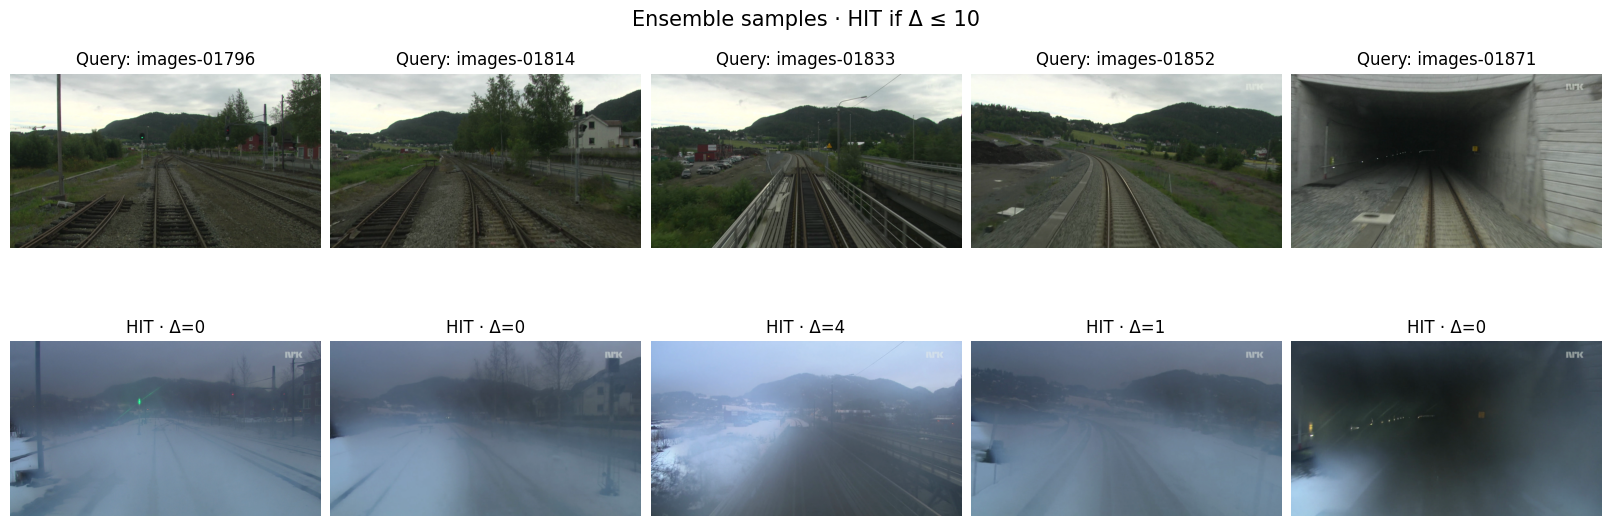

Samples: d:\AIO\Project\Nordland-Cross-Season-VPR\runs\boq_nordland_vpr_ensemble_samples.png


In [11]:
test_candidates = [DATA_ROOT / 'test', WORK_ROOT / 'test', Path('/content/test'), Path('/content/TACVU2/test')]
available = [path for path in test_candidates
             if (path / 'queries').is_dir() and (path / 'database').is_dir()]
if len(available) > 1:
    raise RuntimeError(f'Multiple test folders found: {available}')

if available:
    test_root = available[0]
    test_queries = images_in_folder(test_root / 'queries')
    test_database = images_in_folder(test_root / 'database')
    test_scores = np.zeros((len(test_queries), len(test_database)), dtype=np.float32)
    for fold in range(4):
        checkpoint = WORK_ROOT / f'boq_nordland_clean_fold{fold}_random_{EPOCHS}ep' / 'checkpoints' / 'best.pt'
        payload = torch.load(checkpoint, map_location='cpu', weights_only=False)
        test_model = BoQVPR(CONFIG).to(DEVICE).eval()
        test_model.load_state_dict(payload['model'], strict=True)
        q_desc = encode_images(test_model, test_queries, DEVICE, CONFIG['eval_batch_size'], CONFIG['num_workers'])
        d_desc = encode_images(test_model, test_database, DEVICE, CONFIG['eval_batch_size'], CONFIG['num_workers'])
        test_scores += (q_desc @ d_desc.T) / 4
        del test_model, q_desc, d_desc
        torch.cuda.empty_cache()
    submission = pd.DataFrame({'query_id': test_queries.id.astype(str),
                               'winter_id': test_database.id.to_numpy()[test_scores.argmax(1)]})
    submission_check(submission, test_queries.id, test_database.id)
    source = f'4-checkpoint ensemble test: {test_root}'
else:
    submission = pd.DataFrame({'query_id': ensemble_queries.id.astype(str),
                               'winter_id': ensemble_database.id.to_numpy()[ensemble_pred]})
    submission_check(submission, ensemble_queries.id, ensemble_database.id)
    source = '4-checkpoint ensemble holdout'

OUTPUT_FILE = WORK_ROOT / 'boq_nordland_vpr_ensemble_output.csv'
atomic_csv_save(submission[['query_id', 'winter_id']], OUTPUT_FILE)
exported = pd.read_csv(OUTPUT_FILE, dtype=str)
if available:
    query_ids = images_in_folder(test_root / 'queries').id
    database_ids = images_in_folder(test_root / 'database').id
else:
    query_ids = ensemble_queries.id
    database_ids = ensemble_database.id
submission_check(exported, query_ids, database_ids)

assert len(exported) == len(query_ids)
print('Ensemble holdout Recall@1:', ENSEMBLE_METRICS.iloc[-1].holdout_recall_at_1)
print('Source:', source)
print('Output:', OUTPUT_FILE)
display(exported.head(10))

visual_queries = test_queries if available else ensemble_queries
visual_database = test_database if available else ensemble_database
sample_indices = np.linspace(0, len(visual_queries) - 1, min(5, len(visual_queries)), dtype=int)
database_by_id = visual_database.set_index(visual_database.id.astype(str), drop=False)
fig, axes = plt.subplots(2, len(sample_indices), figsize=(16, 5.5),
                         layout='constrained',
                         gridspec_kw={'hspace': 0.08, 'wspace': 0.03})
axes = np.asarray(axes).reshape(2, len(sample_indices))
for column, query_index in enumerate(sample_indices):
    query = visual_queries.iloc[query_index]
    prediction = database_by_id.loc[str(exported.iloc[query_index].winter_id)]
    with Image.open(query.path) as image:
        axes[0, column].imshow(image.convert('RGB'))
    with Image.open(prediction.path) as image:
        axes[1, column].imshow(image.convert('RGB'))
    axes[0, column].set_title(f'Query: {query.id}')
    if 'position' in visual_queries.columns:
        delta = abs(int(query.position) - int(prediction.position))
        verdict = 'HIT' if delta <= 10 else 'MISS'
        prediction_title = f'{verdict} · Δ={delta}'
    else:
        prediction_title = f'Prediction: {prediction.id}'
    axes[1, column].set_title(prediction_title)
    axes[0, column].axis('off')
    axes[1, column].axis('off')
fig.suptitle('Ensemble samples · HIT if Δ ≤ 10', fontsize=15)
SAMPLES_FILE = WORK_ROOT / 'boq_nordland_vpr_ensemble_samples.png'
fig.savefig(SAMPLES_FILE, dpi=140, bbox_inches='tight')
plt.show()
print('Samples:', SAMPLES_FILE)